In [1]:
import sys
import importlib.util
import subprocess

if importlib.util.find_spec("sionna") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "sionna-rt"
    ])
    print("Sionna RT installed.")
else:
    print("Sionna is already installed.")

Sionna is already installed.


# Setup
Scene, antennas, base station and the two receivers (RX1 at distance r, RX2 at distance 2r).

In [2]:
# Imported Sionna and the functions we will use
# Imported the NumPy library for mathematical operations
import sionna.rt
import mitsuba as mi
from sionna.rt import (
    PlanarArray,
    Transmitter,
    Receiver,
    load_scene,
    PathSolver,
    SceneObject,
    ITURadioMaterial
    )
import numpy as np
import matplotlib.pyplot as plt
#from google.colab import output
#output.enable_custom_widget_manager()

jitc_llvm_init(): LLVM API initialization failed ..


In [3]:
# Called our environment and loaded the scene
scene = load_scene()

In [4]:
# Set our frequency to 7 GHz and the other parameters
scene.frequency = 7e9
tx_power_dbm = 30
c = 299792458.0
r = 20

In [5]:
# Using the PlanarArray function, we defined the number of Tx antenna elements, to be used as our base station, antenna properties and orientation

scene.tx_array= PlanarArray(
    num_rows=1,
    num_cols=1,
    pattern="iso",
    polarization="V",)

In [6]:
# We defined the properties of our receiving antenna
scene.rx_array= PlanarArray(
    num_rows=1,
    num_cols=1,
    pattern="iso",
    polarization="V",
)

In [7]:
# Named our transmitter Base Station 1 and defined its position
bs = Transmitter(
    name="BS1",
    position=[0, 0, 0]
)

In [8]:
# Added our base station to the scene
scene.add(bs)

In [9]:
# Named our first receiver and set its position at a distance of r from the base station
rx1 = Receiver(
    name="RX1",
    position=[r, -5, 5]
)

In [10]:
# Named our second receiver and set its position at a distance of 2*r from the base station
rx2 = Receiver(
    name="RX2",
    position=[2*r, -5, 5]
)

In [11]:
# Added our receivers to the scene
scene.add(rx1)
scene.add(rx2)

In [12]:
# Printed the position of each receiver to make sure their positions were correct
for name in ["RX1", "RX2"]:
    rx = scene.get(name)
    print(name, np.array(rx.position))

RX1 [[20.]
 [-5.]
 [ 5.]]
RX2 [[40.]
 [-5.]
 [ 5.]]


## Free-space reference: RSS and FSPL without the building

In [13]:
# Calculated the wavelength (c and tx_power_dbm are defined in the parameter cell)
# Calculated the free space path loss values for each receiver
# path gain = - path loss
# Calculated the received signal strength (RSS) for each receiver
wavelength = c/ scene.frequency
# Euclidean distance between the base station and each receiver
bs_pos = np.array(bs.position).ravel()
d1 = np.linalg.norm(np.array(rx1.position).ravel() - bs_pos)
d2 = np.linalg.norm(np.array(rx2.position).ravel() - bs_pos)
print(f"Distance BS1-RX1: {d1:.2f} m")
print(f"Distance BS1-RX2: {d2:.2f} m")

fspl1 = 20*np.log10(4*np.pi*d1/wavelength)
fspl2 = 20*np.log10(4*np.pi*d2/wavelength)

rss1 = tx_power_dbm - fspl1
rss2 = tx_power_dbm - fspl2

print(f"RSS at RX1: {rss1} dBm")
print(f"RSS at RX2: {rss2} dBm")

print(f"FSPL at RX1: {fspl1} dB")
print(f"FSPL at RX2: {fspl2} dB")

# Convert received power from dBm to nanowatts for comparing
p_rx1 = 10**((rss1 - 30) / 10) * 1e9
p_rx2 = 10**((rss2 - 30) / 10) * 1e9

print(f"RX1: {p_rx1.item():.2f} nW")
print(f"RX2: {p_rx2.item():.2f} nW")

print(f"RX2 / RX1: {((p_rx2 / p_rx1).item()):.2f}")

Distance BS1-RX1: 21.21 m
Distance BS1-RX2: 40.62 m
RSS at RX1: [-45.881874] dBm
RSS at RX2: [-51.524582] dBm
FSPL at RX1: [75.881874] dB
FSPL at RX2: [81.52458] dB
RX1: 25.81 nW
RX2: 7.04 nW
RX2 / RX1: 0.27


**Explanation:**

| Receiver | Position | Distance to BS1 | FSPL | RSS |
|---|---|---|---|---|
| RX1 | (20, −5, 5) | 21.21 m | 75.88 dB | −45.88 dBm |
| RX2 | (40, −5, 5) | 40.62 m | 81.52 dB | −51.52 dBm |

RSS decreases as the distance increases. The distances are calculated as Euclidean distances from BS1, √(x² + y² + z²). Because both receivers have the same y and z offset, RX2 is not exactly twice as far as RX1 but 1.92 times (40.62 / 21.21). This increases the free-space path loss by 20·log₁₀(1.92) ≈ 5.64 dB, so the RSS drops by 5.64 dB. In linear units the received power falls from 25.81 nW to 7.04 nW, a ratio of 0.27 ≈ (21.21 / 40.62)². This confirms the inverse-square law: the received power is proportional to 1/d². The RSS does not decrease linearly with distance but logarithmically (by 20·log₁₀(d)). The "Without Building" bars in Research Question 1 shows these free-space values.

## Research Question 1: How does a building between the base station and the receiver affect the RSS?

>Write your answers here


In [14]:
# Create a building geometry using Mitsuba
building_mesh = mi.load_dict({
    "type": "cube",
    "to_world": mi.ScalarTransform4f()
        .translate([30, -5, 4])
        .scale([5, 5, 7.5])
})

print(type(building_mesh))

<class 'mitsuba.Mesh'>


In [15]:
# Create a Sionna scene object from the Mitsuba mesh
building1 = SceneObject(
    mi_mesh=building_mesh,
    name="building1",
    radio_material=ITURadioMaterial(
        name="concrete",
        itu_type="concrete"
    )
)

In [16]:
# Add the building to the scene
scene.add(building1)

In [17]:
solver = PathSolver()

paths_with = solver(
    scene,
    max_depth=3,
    los=True,
    specular_reflection=True,
    diffuse_reflection= True,
    diffraction= True,
    refraction= True
)

In [18]:
scene.preview(paths = paths_with)


In [19]:
scene._preview_widget = None

In [20]:
# Remove the building
scene.remove("building1")

# Calculate propagation paths without the building
paths_without = solver(
    scene,
    max_depth=3,
    los=True,
    specular_reflection=True,
    diffuse_reflection=False,
    diffraction=False
)

In [21]:
#if obsticle in between rss ve path gain value changing
# Get channel coefficients

# Calculate path gain and RSS from channel coefficients
def calculate_rss(paths, tx_power_dbm=30):

    a_real, a_imag = paths.a
    a = np.array(a_real) + 1j * np.array(a_imag)

    # Combine propagation paths coherently
    h = np.sum(a, axis=-1)

    # Calculate path gain
    path_gain = np.abs(h)**2
    path_gain_db = 10 * np.log10(path_gain)

    # Calculate received signal strength
    rss_dbm = tx_power_dbm + path_gain_db

    return path_gain_db.reshape(-1), rss_dbm.reshape(-1)

In [22]:
# With building
gain_with, rss_with = calculate_rss(paths_with)

# Without building
gain_without, rss_without = calculate_rss(paths_without)

# Compare results
for i in range(2):
    print(f"RX{i+1}")
    print(f"RSS without building: {rss_without[i]:.2f} dBm")
    print(f"RSS with building:    {rss_with[i]:.2f} dBm")
    print(f"RSS difference:       {rss_with[i] - rss_without[i]:.2f} dB")
    print()

RX1
RSS without building: -45.88 dBm
RSS with building:    -48.65 dBm
RSS difference:       -2.77 dB

RX2
RSS without building: -51.52 dBm
RSS with building:    -88.59 dBm
RSS difference:       -37.07 dB



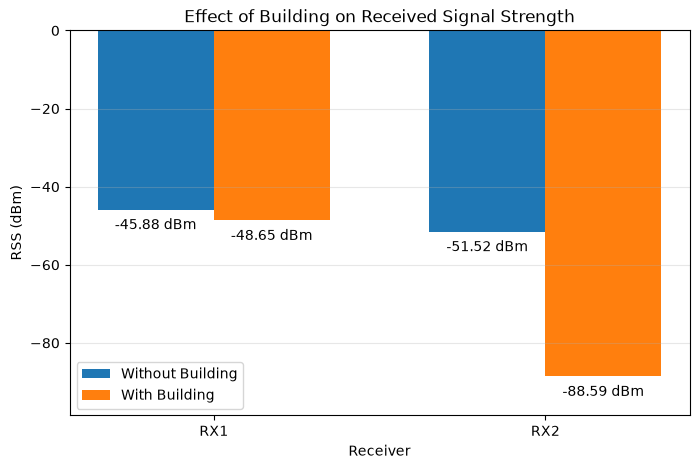

In [23]:
# Grouped bar chart: RSS at each receiver with and without the building
receiver_names = ["RX1", "RX2"]
x = np.arange(len(receiver_names))   # bar group positions
width = 0.35                         # width of each bar

plt.figure(figsize=(8, 5))
bars_without = plt.bar(x - width/2, rss_without, width, label="Without Building")
bars_with = plt.bar(x + width/2, rss_with, width, label="With Building")

# Write the RSS value under each bar
for bar in list(bars_without) + list(bars_with):
    value = bar.get_height()
    plt.annotate(
        f"{value:.2f} dBm",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, -14),
        textcoords="offset points",
        ha="center"
    )

plt.xticks(x, receiver_names)
plt.ylim(min(rss_with) - 10, 0)
plt.xlabel("Receiver")
plt.ylabel("RSS (dBm)")
plt.title("Effect of Building on Received Signal Strength")
plt.legend(loc="lower left")
plt.grid(axis="y", alpha=0.3)
plt.show()

**Explanation:**

| Receiver | Without building | With building | Difference |
|---|---|---|---|
| RX1 (21.21 m, in front of the building) | −45.88 dBm | −48.65 dBm | −2.77 dB |
| RX2 (40.62 m, behind the building) | −51.52 dBm | −88.59 dBm | −37.07 dB |

- **RX1:** The building does not block the line of sight to RX1. However, the signal reflected from the front face of the building also reaches RX1. This reflected path is 9.61 m longer than the direct path (30.82 m vs. 21.21 m) and arrives roughly out of phase, so the two signals partly cancel each other (destructive interference) and the RSS drops by 2.77 dB.
- **RX2:** The building blocks the line of sight, so the signal can only reach RX2 through the building (refraction at the front and back walls, 40.62 m). The walls reflect and absorb most of the energy. A second path (43.01 m), which is also reflected from the inner side wall of the building, interferes destructively with the first one. A third path reflected from the inner surface of the roof is more than 30 dB weaker and has no visible effect. Together, the RSS drops by 37.07 dB. This loss is much larger than the effect of distance (5.64 dB between RX1 and RX2).

## Research Question 2: Which building material reduces the RSS at RX2 the most?

>Write your answers here


In [24]:

# Remove the concrete building from the scene
if scene.get("building1") is not None:
    scene.remove("building1")

# Materials to compare
materials = ["concrete", "glass", "brick", "wood"]
material_results = {}

for material_name in materials:

    # Create a building with the selected material
    building2 = SceneObject(
        mi_mesh=building_mesh,
        name="building2",
        radio_material=ITURadioMaterial(
            name=f"material_{material_name}",
            itu_type=material_name
        )
    )

    scene.add(building2)

    # Calculate propagation paths
    paths = solver(
        scene,
        max_depth=3,
        los=True,
        specular_reflection=True,
        diffuse_reflection=False,
        diffraction=False,
        edge_diffraction= False,
        refraction=True
    )

    # Calculate RSS and path gain
    gain, rss = calculate_rss(paths, tx_power_dbm)

    material_results[material_name] = {
        "gain": gain.copy(),
        "rss": rss.copy()
    }

    # Print results
    print(f"\nMaterial: {material_name.upper()}")

    for i in range(2):
        print(f"RX{i+1}")
        print(f"  RSS:       {rss[i]:.2f} dBm")
        print(f"  Path Gain: {gain[i]:.2f} dB")

    # Remove building before testing the next material
    scene.remove("building2")


Material: CONCRETE
RX1
  RSS:       -48.65 dBm
  Path Gain: -78.65 dB
RX2
  RSS:       -88.59 dBm
  Path Gain: -118.59 dB

Material: GLASS
RX1
  RSS:       -49.53 dBm
  Path Gain: -79.53 dB
RX2
  RSS:       -67.14 dBm
  Path Gain: -97.14 dB

Material: BRICK
RX1
  RSS:       -47.98 dBm
  Path Gain: -77.98 dB
RX2
  RSS:       -59.02 dBm
  Path Gain: -89.02 dB

Material: WOOD
RX1
  RSS:       -47.09 dBm
  Path Gain: -77.09 dB
RX2
  RSS:       -62.16 dBm
  Path Gain: -92.16 dB


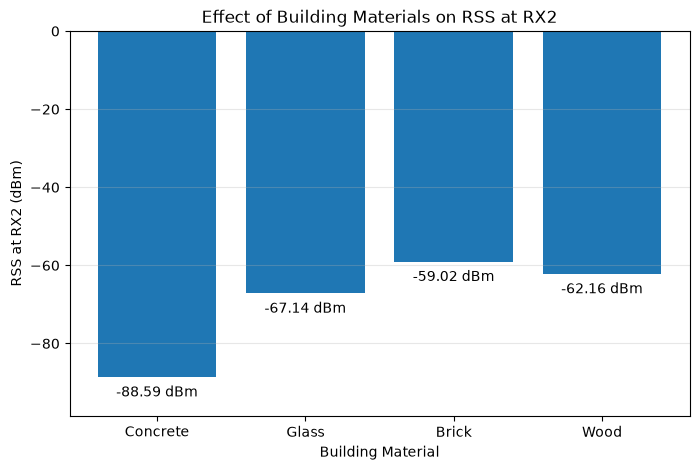

In [25]:
# RSS at RX2 for each building material
material_names = [m.capitalize() for m in material_results]
rss_rx2 = [results["rss"][1] for results in material_results.values()]   # index 1 = RX2

plt.figure(figsize=(8, 5))
bars = plt.bar(material_names, rss_rx2)

# Write the RSS value under each bar
for bar, value in zip(bars, rss_rx2):
    plt.annotate(
        f"{value:.2f} dBm",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, -14),
        textcoords="offset points",
        ha="center"
    )

plt.ylim(min(rss_rx2) - 10, 0)
plt.xlabel("Building Material")
plt.ylabel("RSS at RX2 (dBm)")
plt.title("Effect of Building Materials on RSS at RX2")
plt.grid(axis="y", alpha=0.3)
plt.show()

**Explanation:**

| Material | Relative permittivity ε_r | Conductivity σ (at 7 GHz) | RSS at RX2 | Additional loss caused by the building (reference: −51.52 dBm without building) |
|---|---|---|---|---|
| Concrete | 5.24 | 0.212 S/m | −88.59 dBm | 37.07 dB |
| Glass | 6.31 | 0.049 S/m | −67.14 dBm | 15.62 dB |
| Wood | 1.99 | 0.038 S/m | −62.16 dBm | 10.64 dB |
| Brick | 3.91 | 0.033 S/m | −59.02 dBm | 7.50 dB |

Concrete reduces the RSS at RX2 the most, by about 37 dB, which is roughly 21 dB more than any other material. At 7 GHz it has a much higher conductivity (σ ≈ 0.21 S/m) than the other materials, so it absorbs much more energy inside its walls.

Contrary to our expectation, glass gives a lower RSS than brick and wood. At 7 GHz, glass has the highest relative permittivity (ε_r = 6.31), so it reflects the largest part of the incoming wave at its surface (|Γ| ≈ 0.43), and its conductivity grows quickly with frequency (σ ∝ f^1.34). Glass is transparent to visible light, but not to 7 GHz radio waves. In this geometry, the second path reflected from the inner side wall also interferes destructively with the direct path, which lowers the RSS further. Brick has the lowest conductivity at this frequency and therefore gives the smallest loss.

The result shows that the material of an obstacle can affect the RSS more than the distance: concrete alone causes more loss than moving the receiver 40 times farther away in free space (20·log₁₀(40) ≈ 32 dB).